# Automatska kategorizacija proizvoda
### IT Akademija | Task 3 | Nikola Novkov

**Poslovni cilj:** na osnovu samog naziva proizvoda predložiti jednu od 10 kategorija pri unosu u online prodavnicu. Sveska dokumentuje istraživanje originalnog kataloga, čišćenje, inženjering karakteristika, upoređivanje četiri modela, evaluaciju i zaključak.

**Metodološka napomena:** tokom evaluacije karakteristike TF–IDF učimo isključivo na trening podacima. Identiczne naslove uklanjamo pre podele kako ista poruka ne bi završila i u treningu i u testu.

## 1. Učitavanje i pregled originalnih podataka

Proveravamo strukturu kolona, broj redova, nedostajuće vrednosti i neujednačene nazive kategorija. Identifikatori, pregledi, ocena prodavca i datum nisu dostupni kada korisnik samo unosi naziv proizvoda, pa ne smeju biti ulazne promenljive modela.

In [1]:
from pathlib import Path
import io
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from joblib import dump

# Podrzava pokretanje sveske iz korena projekta ili iz notebooks/ fascikle.
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "data" / "products.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Nije pronadjen data/products.csv. Pokreni notebook iz korena repozitorijuma.")
sys.path.insert(0, str(ROOT))
from src.data_utils import read_raw_data, clean_data
from train_model import build_models
plt.switch_backend("module://matplotlib_inline.backend_inline")

pd.set_option("display.max_colwidth", 65)
raw = read_raw_data(str(ROOT / "data" / "products.csv"))
print("Dimenzije skupa:", raw.shape)
display(raw.head(5))

# PNG se cuva u izlazu notebooka i u headless okruzenju (GitHub prikaz).
def show_figure(fig):
    png = io.BytesIO()
    fig.savefig(png, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=png.getvalue()))
    plt.close(fig)


Dimenzije skupa: (35311, 8)


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphon...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


In [2]:
missing = raw.isna().sum().to_frame("Praznih vrednosti")
missing["Udeo (%)"] = (100 * missing["Praznih vrednosti"] / len(raw)).round(2)
display(missing)
print("Sirove vrednosti Category Label:")
display(raw["Category Label"].value_counts(dropna=False).to_frame("Broj"))

,Praznih vrednosti,Udeo (%)
product ID,0,0.00
Product Title,172,0.49
Merchant ID,0,0.00
Category Label,44,0.12
_Product Code,95,0.27
Number_of_Views,14,0.04
Merchant Rating,170,0.48
Listing Date,59,0.17


Sirove vrednosti Category Label:


,Broj
Category Label,
Fridge Freezers,5495
Washing Machines,4036
Mobile Phones,4020
CPUs,3771
TVs,3564
Fridges,3457
Dishwashers,3418
Digital Cameras,2696
Microwaves,2338


## 2. Čišćenje i normalizacija

Tri kategorije imaju alternativna imena: `CPU` → `CPUs`, `Mobile Phone` → `Mobile Phones` i `fridge` → `Fridges`. Brišemo prazne naslove i oznake, zatim naslove koji imaju kontradiktorne kategorije. Na kraju uklanjamo ponovljene naslove (ne samo duplikate svih kolona).

In [3]:
cleaned, stats = clean_data(raw)
display(pd.DataFrame([{
    "Polaznih proizvoda": stats["raw_rows"],
    "Neispravnih redova": stats["invalid_or_unknown_rows"],
    "Kontradiktornih naslova": stats["ambiguous_title_groups"],
    "Uklonjenih ponavljanja": stats["duplicate_title_rows_removed"],
    "Za model": stats["clean_rows"],
    "Kategorija": stats["n_categories"],
}]))
display(cleaned[["title", "category"]].head())

,Polaznih proizvoda,Neispravnih redova,Kontradiktornih naslova,Uklonjenih ponavljanja,Za model,Kategorija
0,35311,215,2,4270,30822,10


,title,category
0,apple iphone 8 plus 64gb silver,Mobile Phones
1,apple iphone 8 plus 64 gb spacegrau,Mobile Phones
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphon...,Mobile Phones
3,apple iphone 8 plus 64gb space grey,Mobile Phones
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free,Mobile Phones


## 3. EDA i izvedene karakteristike

Istražujemo broj reči, broj karaktera i prisustvo cifara u naslovu. Ove karakteristike pomažu da razumemo format podataka; zatim testiramo TF–IDF reči i karakterskih n-grama. Posebno su važni fragmenti šifara (`kgv39vl31g`) koje tradicionalni model zasnovan samo na rečima ne prepoznaje dobro.

Osnovne statistike naslova:


,characters,words
count,30822.0,30822.0
mean,52.8,8.6
std,22.6,4.2
min,5.0,1.0
25%,38.0,6.0
50%,51.0,8.0
75%,65.0,11.0
max,200.0,37.0


Naslova koji sadrze cifru: 96.6%


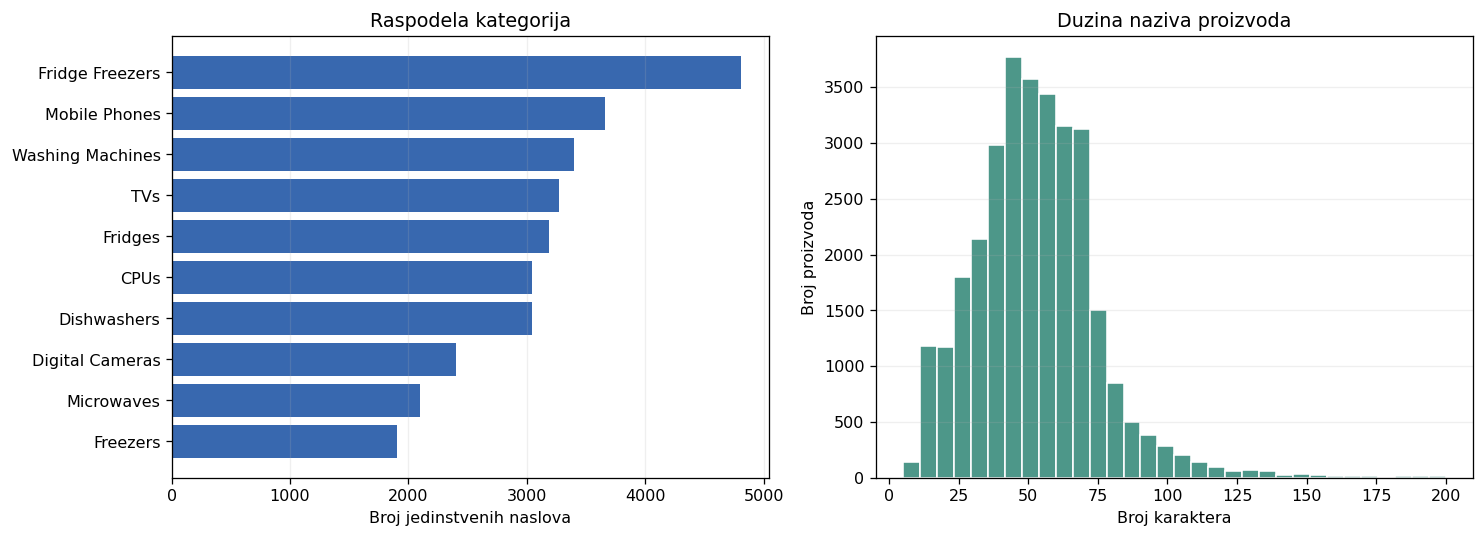

In [4]:
eda = cleaned[["title", "category"]].copy()
eda["characters"] = eda["title"].str.len()
eda["words"] = eda["title"].str.split().str.len()
eda["has_digit"] = eda["title"].str.contains(r"\d", regex=True)
print("Osnovne statistike naslova:")
display(eda[["characters", "words"]].describe().round(1))
print(f"Naslova koji sadrze cifru: {eda['has_digit'].mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
counts = eda["category"].value_counts().sort_values()
axes[0].barh(counts.index, counts.values, color="#3868af")
axes[0].set(title="Raspodela kategorija", xlabel="Broj jedinstvenih naslova")
axes[0].grid(axis="x", alpha=.2)
axes[1].hist(eda["characters"], bins=32, color="#4d9789", edgecolor="white")
axes[1].set(title="Duzina naziva proizvoda", xlabel="Broj karaktera", ylabel="Broj proizvoda")
axes[1].grid(axis="y", alpha=.2)
fig.tight_layout()
show_figure(fig)

## 4. Podela podataka i zaštita od curenja informacija

Koristimo 80% naslova za treniranje i 20% za testiranje, `random_state=42` i `stratify=y`. Najpre delimo podatke, **pa tek onda** prilagođavamo TF–IDF vektorizatore na trening delu pomoću `Pipeline` i `fit`. Tako test skup ostaje neviđen tokom treniranja.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    cleaned["title"].astype(str), cleaned["category"].astype(str),
    test_size=0.20, stratify=cleaned["category"], random_state=42,
)
print(f"Trening: {len(X_train)} | Test: {len(X_test)}")
print("Udeo test kategorija:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("%"))

Trening: 24657 | Test: 6165
Udeo test kategorija:


,%
category,
Fridge Freezers,15.60
Mobile Phones,11.87
Washing Machines,11.03
TVs,10.62
Fridges,10.35
CPUs,9.88
Dishwashers,9.86
Digital Cameras,7.80
Microwaves,6.80


## 5. Treniranje i poređenje četiri modela

Testiramo dva klasična modela sa TF–IDF reči i dve varijante **Linear SVC** klasifikatora sa karakterskim, odnosno kombinovanim n-gramima. Time merimo da li delovi naziva modela uređaja daju više informacija od celih reči.

In [6]:
models = build_models()
rows, predicted, fitted = [], {}, {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    guess = pipeline.predict(X_test)
    predicted[name] = guess
    fitted[name] = pipeline
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, guess),
        "Precision macro": precision_score(y_test, guess, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, guess, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, guess, average="macro", zero_division=0),
    })
results = pd.DataFrame(rows).sort_values(["F1 macro", "Accuracy"], ascending=False).reset_index(drop=True)
display(results.style.format({c:"{:.2%}" for c in ["Accuracy","Precision macro","Recall macro","F1 macro"]}))
best_name = results.loc[0, "Model"]
print("Najbolji model (macro F1):", best_name)

,Model,Accuracy,Precision macro,Recall macro,F1 macro
0,Linear SVC / char,98.99%,99.03%,98.98%,99.00%
1,Linear SVC / word+char,98.83%,98.89%,98.78%,98.83%
2,Multinomial Naive Bayes / word,95.60%,96.76%,95.07%,95.77%
3,Logistic Regression / word,95.26%,95.81%,95.21%,95.49%


Najbolji model (macro F1): Linear SVC / char


## 6. Vizuelno poređenje performansi

Tačnost (`accuracy`) je intuitivna, ali model može dobijati visok skor na brojnijim kategorijama. **Macro F1** daje podjednaku težinu svim kategorijama, pa je primarna metrika za izbor.

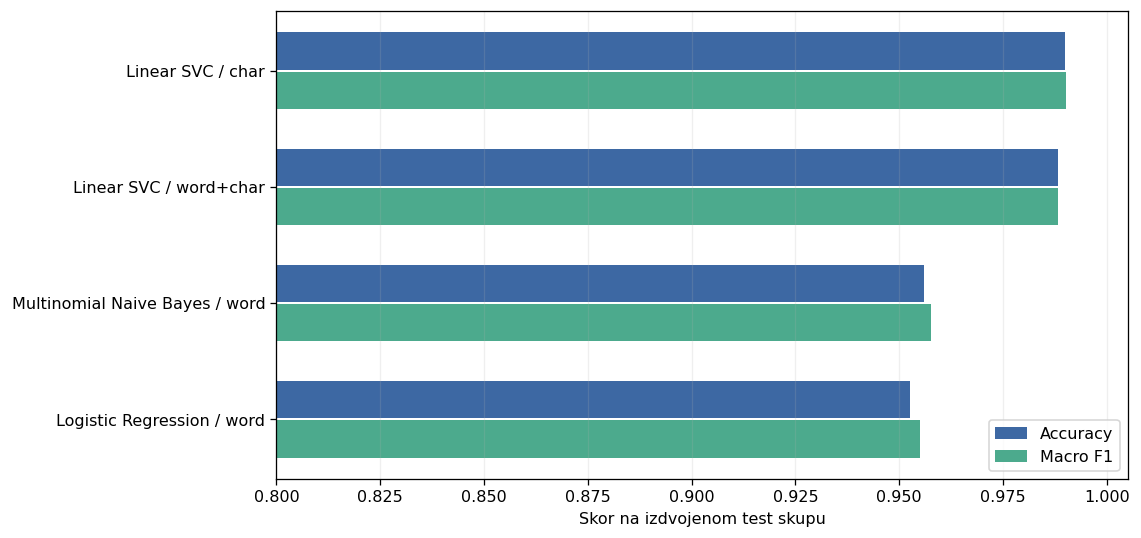

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ix = np.arange(len(results))
ax.barh(ix-.17, results["Accuracy"], height=.32, label="Accuracy", color="#3d68a3")
ax.barh(ix+.17, results["F1 macro"], height=.32, label="Macro F1", color="#4caa8d")
ax.set_yticks(ix, results["Model"])
ax.set_xlim(.8, 1.005)
ax.set_xlabel("Skor na izdvojenom test skupu")
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=.2)
fig.tight_layout();show_figure(fig)

## 7. Matrice zabune za sve modele

Svaki red predstavlja stvarnu kategoriju, a kolona kategoriju koju je model predvideo. Vrednosti su normalizovane **po stvarnoj klasi**, kako bi kategorije različitih veličina bile uporedive. Dijagonala predstavlja tačna predviđanja.

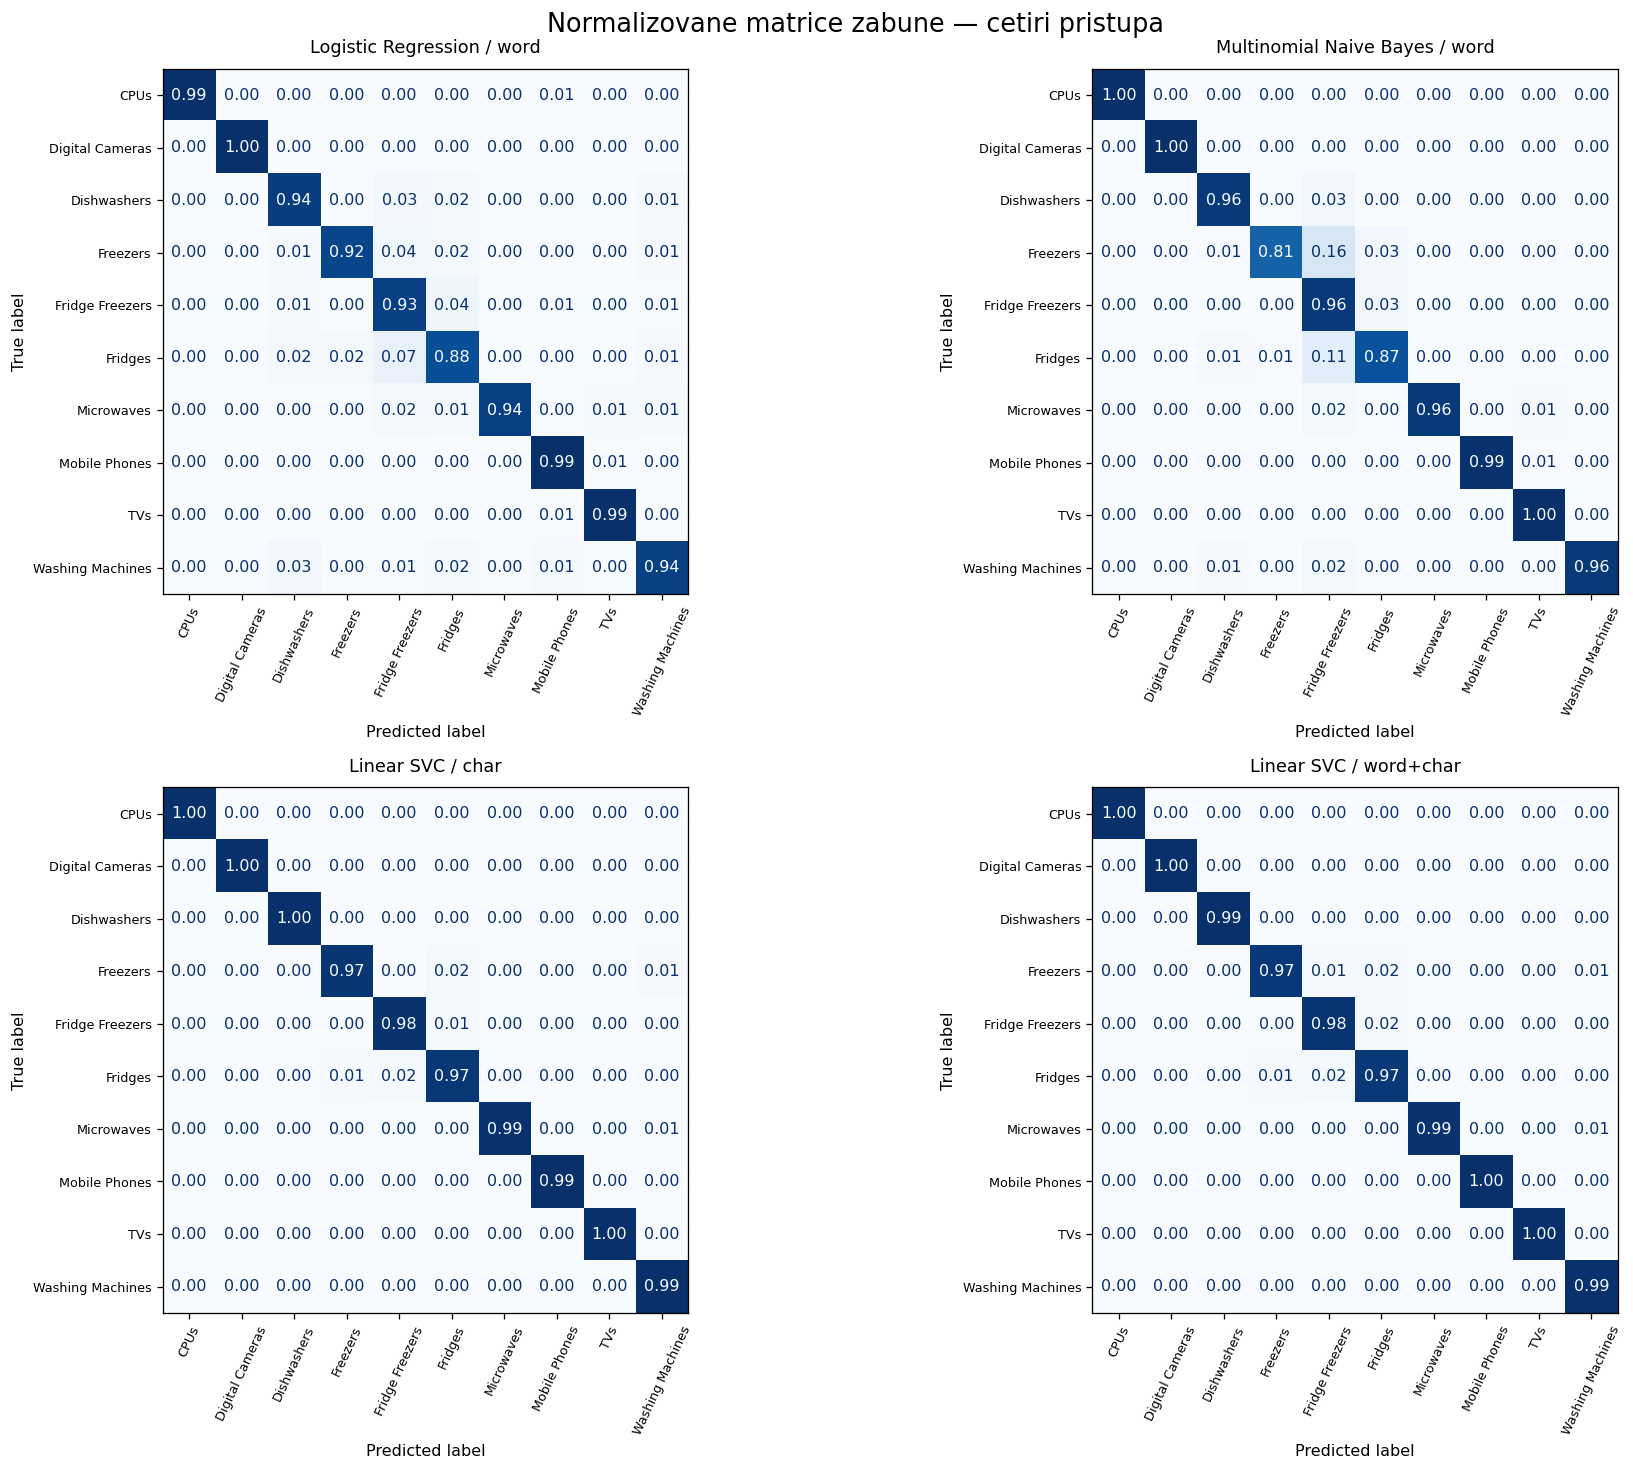

In [8]:
labels = sorted(cleaned["category"].unique())
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
for ax, (name, guesses) in zip(axes.flat, predicted.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, guesses, labels=labels, normalize="true",
        cmap="Blues", values_format=".2f", ax=ax, colorbar=False,
        xticks_rotation=65,
    )
    ax.set_title(name, fontsize=11, pad=10)
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Normalizovane matrice zabune — cetiri pristupa", fontsize=16)
fig.tight_layout();show_figure(fig)

## 8. Detaljan izveštaj najboljeg modela i analiza grešaka

Pored ukupne tačnosti gledamo `precision`, `recall` i `F1` za svaku kategoriju. Pregled stvarno pogrešnih naslova pomaže da razumemo gde su granice sistema.

In [9]:
best_pred = predicted[best_name]
print(classification_report(y_test, best_pred, zero_division=0))
error_frame = pd.DataFrame({
    "Naziv proizvoda": X_test.to_numpy(),
    "Stvarna kategorija": y_test.to_numpy(),
    "Predlog modela": best_pred,
})
errors = error_frame[error_frame["Stvarna kategorija"] != error_frame["Predlog modela"]]
print(f"Pogresnih predvidjanja: {len(errors)} od {len(error_frame)}")
display(errors.head(15))

                  precision    recall  f1-score   support

            CPUs       1.00      1.00      1.00       609
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       1.00      1.00      1.00       608
        Freezers       0.98      0.97      0.98       381
 Fridge Freezers       0.98      0.98      0.98       962
         Fridges       0.96      0.97      0.97       638
      Microwaves       1.00      0.99      0.99       419
   Mobile Phones       1.00      0.99      1.00       732
             TVs       1.00      1.00      1.00       655
Washing Machines       0.99      0.99      0.99       680

        accuracy                           0.99      6165
       macro avg       0.99      0.99      0.99      6165
    weighted avg       0.99      0.99      0.99      6165

Pogresnih predvidjanja: 62 od 6165


,Naziv proizvoda,Stvarna kategorija,Predlog modela
128,zanussi zwy61225wi eek a skala a bis d zwy61225wi,Washing Machines,Fridges
153,bosch stand k hlger t gsn36bi30,Freezers,Fridges
387,amica ziv635,Dishwashers,Fridge Freezers
393,zanussi zbt20420sa 122cm doppeltrger t eek a skala a bis d zb...,Fridge Freezers,Fridges
417,cda fw321/fw321,Fridges,Fridge Freezers
591,siemens ki28da20 eingebaut 255l a wei k hl,Fridge Freezers,Fridges
660,smeg fab5rpk fridge freezer,Fridges,Fridge Freezers
669,liebherr bp2850 white biofresh fridge freezer,Fridges,Fridge Freezers
699,miele kf 37122 id eingebaut 287l a wei,Fridge Freezers,Fridges
716,bosch k hlschrank integrierbar kin86af30,Fridge Freezers,Fridges


## 9. Ručna provera na primerima iz zadatka

Šest naslova iz instrukcije služi kao dodatna demonstracija rada. Rezultati nisu zamena za veliki, odvojeni test skup iz prethodnih sekcija.

In [10]:
examples = [
    ("iphone 7 32gb gold,4,3,Apple iPhone 7 32GB", "Mobile Phones"),
    ("olympus e m10 mark iii geh use silber", "Digital Cameras"),
    ("kenwood k20mss15 solo", "Microwaves"),
    ("bosch wap28390gb 8kg 1400 spin", "Washing Machines"),
    ("bosch serie 4 kgv39vl31g", "Fridge Freezers"),
    ("smeg sbs8004po", "Fridge Freezers"),
]
test_names = [x[0] for x in examples]
test_expected = [x[1] for x in examples]
test_got = fitted[best_name].predict(test_names)
manual_test = pd.DataFrame({"Naziv": test_names, "Ocekivano": test_expected, "Predvidjeno": test_got})
manual_test["Tacno"] = manual_test["Ocekivano"] == manual_test["Predvidjeno"]
display(manual_test)
print(f"Pogodjeno: {int(manual_test['Tacno'].sum())}/{len(manual_test)}")

,Naziv,Ocekivano,Predvidjeno,Tacno
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,True
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,True
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,True
5,smeg sbs8004po,Fridge Freezers,Fridge Freezers,True


Pogodjeno: 6/6


## 10. Finalni model: ponovno treniranje i serijalizacija

Pošto smo izbor modela završili na izdvojenom test skupu, sada ponovo treniramo najbolji algoritam na **celom očišćenom skupu**. Ovaj korak koristi više podataka za praktičnu primenu. Skorovi iz tabele iznad pripadaju isključivo odvojenoj evaluaciji, ne ponovo treniranom modelu.

In [11]:
final_model = build_models()[best_name]
final_model.fit(cleaned["title"].astype(str), cleaned["category"].astype(str))
model_file = ROOT / "models" / "product_category_model.pkl"
model_file.parent.mkdir(exist_ok=True)
dump(final_model, model_file, compress=3)
print("Sacuvan model:", model_file)
print("Velicina:", round(model_file.stat().st_size / (1024**2), 2), "MB")

Sacuvan model: /mnt/data/Nikola_Novkov_Task3_ProductClassifier/models/product_category_model.pkl
Velicina: 3.65 MB


## 11. Zaključak i preporuka timu

**Kriterijum za izbor:** najveći **macro F1**, uz proveru ukupne tačnosti i matrice zabune. Za naslove modela uređaja karakterski TF–IDF posebno dobro prepoznaje šifre i varijacije u pisanju.

- **Najvažnija odluka:** oslanjanje na naslov proizvoda kao jedini ulaz, da bi model mogao da radi i za nove proizvode bez metapodataka.
- **Najveći izazov:** ponovljeni naslovi, nedosledne kategorije i brojčano-slovne oznake uređaja.
- **Potencijalna greška:** model može mešati srodne kategorije poput *Fridges* i *Fridge Freezers*; za nejasne slučajeve treba predvideti ručnu proveru.
- **Sledeća verzija:** više validiranih podataka, test sa potpuno novim brendovima i prag pouzdanosti / ručna revizija teže klasifikovanih unosa.

**Ograničenje merenja:** iako su identični naslovi uklonjeni, slični nazivi istog modela mogu biti u oba skupa. Rezultati na potpuno novim modelima ili u produkciji mogu biti slabiji.

In [12]:
winner = results.iloc[0]
display(Markdown(
    f"**Empirijski zaključak:** pobednik je **{winner['Model']}** sa "
    f"**{winner['Accuracy']:.2%}** accuracy i **{winner['F1 macro']:.2%}** macro F1 "
    f"na {len(X_test):,} izdvojenih test primera. "
    f"Od šest demonstracionih naslova tačno je klasifikovano "
    f"**{int(manual_test['Tacno'].sum())}/{len(manual_test)}**."
))

**Empirijski zaključak:** pobednik je **Linear SVC / char** sa **98.99%** accuracy i **99.00%** macro F1 na 6,165 izdvojenih test primera. Od šest demonstracionih naslova tačno je klasifikovano **6/6**.

## 12. Ponovljivost i GitHub predaja

Skripte `train_model.py` i `predict_category.py` koriste iste rutine i isti sačuvani model. Komande za instalaciju, ponovno treniranje, testiranje i objavljivanje javnog GitHub repozitorijuma nalaze se u `README.md`. Zahtev za predaju je **javni URL GitHub repozitorijuma**, a ne samo ZIP datoteka.